In [34]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib xgboost

Note: you may need to restart the kernel to use updated packages.


In [35]:
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)

print("Libraries imported successfully.")

Libraries imported successfully.


In [36]:
PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

FEATURE_DIR = PROJECT_DIR / "data" / "features"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
CHART_DIR = PROJECT_DIR / "outputs" / "charts"
FORECAST_DIR = PROJECT_DIR / "data" / "forecasts"

for folder in [
    FEATURE_DIR,
    MODEL_DIR,
    REPORT_DIR,
    CHART_DIR,
    FORECAST_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

INSTRUMENTS = [
    "NIFTY50",
    "BANKNIFTY",
    "RELIANCE",
    "TCS",
    "HDFCBANK",
    "INFY",
    "ICICIBANK",
    "SBIN",
    "ITC",
    "LT"
]

BEST_MODELS_FILE = (
    REPORT_DIR / "return_based_best_models.csv"
)

FINAL_MODELS_FILE = (
    REPORT_DIR / "return_based_final_models.csv"
)

# Research signal settings
BUY_THRESHOLD_PCT = 0.25
SELL_THRESHOLD_PCT = -0.25

# Risk-level settings
ATR_MULTIPLIER = 1.5
TARGET_1_R = 1.0
TARGET_2_R = 2.0
TARGET_3_R = 3.0

print("Project configured.")
print("Instruments:", len(INSTRUMENTS))

Project configured.
Instruments: 10


In [37]:
if not BEST_MODELS_FILE.exists():
    raise FileNotFoundError(
        "Return-based best-model report not found. "
        "Complete Notebook 08 first."
    )

if not FINAL_MODELS_FILE.exists():
    raise FileNotFoundError(
        "Return-based final-model report not found. "
        "Run Notebook 08 Cell 14 first."
    )

best_models_df = pd.read_csv(BEST_MODELS_FILE)
final_models_df = pd.read_csv(FINAL_MODELS_FILE)

print("Best model selections:")
display(
    best_models_df[
        ["Instrument", "Best_Model", "Mean_Price_RMSE"]
    ]
)

print("\nFinal model metadata:")
display(
    final_models_df[
        ["instrument", "selected_model", "model_file"]
    ]
)

Best model selections:


,Instrument,Best_Model,Mean_Price_RMSE
0,BANKNIFTY,Zero Return Baseline,664.688814
1,HDFCBANK,Gradient Boosting,12.156736
2,ICICIBANK,Zero Return Baseline,18.621060
3,INFY,Zero Return Baseline,24.959613
4,ITC,Linear Regression,3.917680
5,LT,Zero Return Baseline,62.839851
6,NIFTY50,Zero Return Baseline,222.340956
7,RELIANCE,Gradient Boosting,20.104428
8,SBIN,Zero Return Baseline,16.918146
9,TCS,Zero Return Baseline,48.638510



Final model metadata:


,instrument,selected_model,model_file
0,NIFTY50,Zero Return Baseline,NaN
1,BANKNIFTY,Zero Return Baseline,NaN
2,RELIANCE,Gradient Boosting,C:\Users\adity\Downloads\Historical data\Bhara...
3,TCS,Zero Return Baseline,NaN
4,HDFCBANK,Gradient Boosting,C:\Users\adity\Downloads\Historical data\Bhara...
5,INFY,Zero Return Baseline,NaN
6,ICICIBANK,Zero Return Baseline,NaN
7,SBIN,Zero Return Baseline,NaN
8,ITC,Linear Regression,C:\Users\adity\Downloads\Historical data\Bhara...
9,LT,Zero Return Baseline,NaN


In [38]:
def safe_float(value):
    try:
        result = float(value)

        if np.isfinite(result):
            return result

        return np.nan

    except (ValueError, TypeError):
        return np.nan


def reconstruct_price(current_price, predicted_return_pct):
    return current_price * (
        1 + predicted_return_pct / 100
    )


def get_next_business_day(date_value):
    """
    Estimates the next weekday.
    NSE/BSE exchange holidays are not considered.
    """

    return (
        pd.Timestamp(date_value)
        + pd.offsets.BDay(1)
    ).date()


def load_latest_feature_data(symbol):

    file_path = (
        FEATURE_DIR / f"{symbol}_features_full.csv"
    )

    if not file_path.exists():
        raise FileNotFoundError(
            f"Feature file missing: {file_path}"
        )

    df = pd.read_csv(file_path)

    if "date" not in df.columns:
        raise ValueError("Date column is missing.")

    df["date"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

    df = (
        df.dropna(subset=["date"])
        .sort_values("date")
        .reset_index(drop=True)
    )

    if df.empty:
        raise ValueError("No valid historical data.")

    return df


print("Helper functions ready.")

Helper functions ready.


In [39]:
forecast_records = []
forecast_errors = []

for symbol in INSTRUMENTS:

    print("\n" + "=" * 65)
    print("FORECASTING:", symbol)
    print("=" * 65)

    try:
        selected_row = best_models_df[
            best_models_df["Instrument"] == symbol
        ]

        metadata_row = final_models_df[
            final_models_df["instrument"] == symbol
        ]

        if selected_row.empty or metadata_row.empty:
            raise ValueError(
                "Model selection or final-model metadata missing."
            )

        selected_model = selected_row["Best_Model"].iloc[0]

        metadata = metadata_row.iloc[0]

        if metadata["selected_model"] != selected_model:
            raise ValueError(
                "Model selection and saved-model metadata disagree."
            )

        df = load_latest_feature_data(symbol)

        latest = df.iloc[-1]

        current_close = safe_float(
            latest.get("close")
        )

        if not np.isfinite(current_close) or current_close <= 0:
            raise ValueError("Invalid latest closing price.")

        latest_date = latest["date"]

        if selected_model == "Zero Return Baseline":

            predicted_return_pct = 0.0

            model_type = "Zero Return Baseline"

        else:

            model_path_value = metadata["model_file"]
            feature_path_value = metadata["feature_file"]

            if pd.isna(model_path_value) or pd.isna(feature_path_value):
                raise ValueError(
                    "Selected ML model has no saved model or feature path."
                )

            model_path = Path(model_path_value)
            feature_path = Path(feature_path_value)

            if not model_path.exists():
                raise FileNotFoundError(
                    f"Model file not found: {model_path}"
                )

            if not feature_path.exists():
                raise FileNotFoundError(
                    f"Model feature file not found: {feature_path}"
                )

            model = joblib.load(model_path)

            with open(
                feature_path,
                "r",
                encoding="utf-8"
            ) as file:
                feature_columns = json.load(file)

            missing_features = [
                feature
                for feature in feature_columns
                if feature not in df.columns
            ]

            if missing_features:
                raise ValueError(
                    f"Missing features: {missing_features}"
                )

            X_latest = pd.DataFrame(
                [latest[feature_columns].to_dict()],
                columns=feature_columns
            )

            X_latest = X_latest.replace(
                [np.inf, -np.inf],
                np.nan
            )

            predicted_return_pct = float(
                model.predict(X_latest)[0]
            )

            if not np.isfinite(predicted_return_pct):
                raise ValueError(
                    "Model returned a non-finite forecast."
                )

            model_type = selected_model

        predicted_close = reconstruct_price(
            current_close,
            predicted_return_pct
        )

        if (
            not np.isfinite(predicted_close)
            or predicted_close <= 0
        ):
            raise ValueError("Invalid reconstructed forecast price.")

        forecast_records.append({
            "Instrument": symbol,
            "Model": model_type,
            "Last_Data_Date": latest_date.date(),
            "Estimated_Next_Session": get_next_business_day(
                latest_date
            ),
            "Current_Close": current_close,
            "Predicted_Next_Return_Pct": predicted_return_pct,
            "Predicted_Next_Close": predicted_close,
            "Expected_Change": predicted_close - current_close,
            "Expected_Change_Percent": predicted_return_pct,
            "Forecast_Status": "Success"
        })

        print("Selected model:", model_type)
        print("Current close:", round(current_close, 2))
        print("Predicted return (%):", round(predicted_return_pct, 4))
        print("Predicted close:", round(predicted_close, 2))

    except Exception as error:

        print("ERROR:", error)

        forecast_errors.append({
            "Instrument": symbol,
            "Error": str(error)
        })


forecast_df = pd.DataFrame(forecast_records)
forecast_errors_df = pd.DataFrame(forecast_errors)

print("\nForecast generation finished.")
print("Successful:", len(forecast_df))
print("Errors:", len(forecast_errors_df))

display(forecast_df)


FORECASTING: NIFTY50
Selected model: Zero Return Baseline
Current close: 25349.65
Predicted return (%): 0.0
Predicted close: 25349.65

FORECASTING: BANKNIFTY
Selected model: Zero Return Baseline
Current close: 62585.35
Predicted return (%): 0.0
Predicted close: 62585.35

FORECASTING: RELIANCE
Selected model: Gradient Boosting
Current close: 1351.0
Predicted return (%): 0.1874
Predicted close: 1353.53

FORECASTING: TCS
Selected model: Zero Return Baseline
Current close: 2460.0
Predicted return (%): 0.0
Predicted close: 2460.0

FORECASTING: HDFCBANK
Selected model: Gradient Boosting
Current close: 817.8
Predicted return (%): -0.2911
Predicted close: 815.42

FORECASTING: INFY
Selected model: Zero Return Baseline
Current close: 1103.4
Predicted return (%): 0.0
Predicted close: 1103.4

FORECASTING: ICICIBANK
Selected model: Zero Return Baseline
Current close: 1585.5
Predicted return (%): 0.0
Predicted close: 1585.5

FORECASTING: SBIN
Selected model: Zero Return Baseline
Current close: 1132

,Instrument,Model,Last_Data_Date,Estimated_Next_Session,Current_Close,Predicted_Next_Return_Pct,Predicted_Next_Close,Expected_Change,Expected_Change_Percent,Forecast_Status
0,NIFTY50,Zero Return Baseline,2026-11-23,2026-11-24,25349.650391,0.000000,25349.650391,0.000000,0.000000,Success
1,BANKNIFTY,Zero Return Baseline,2026-11-23,2026-11-24,62585.351562,0.000000,62585.351562,0.000000,0.000000,Success
2,RELIANCE,Gradient Boosting,2026-11-23,2026-11-24,1351.000000,0.187375,1353.531436,2.531436,0.187375,Success
3,TCS,Zero Return Baseline,2026-11-23,2026-11-24,2460.000000,0.000000,2460.000000,0.000000,0.000000,Success
4,HDFCBANK,Gradient Boosting,2026-11-23,2026-11-24,817.799988,-0.291074,815.419585,-2.380403,-0.291074,Success
5,INFY,Zero Return Baseline,2026-11-23,2026-11-24,1103.400024,0.000000,1103.400024,0.000000,0.000000,Success
6,ICICIBANK,Zero Return Baseline,2026-11-23,2026-11-24,1585.500000,0.000000,1585.500000,0.000000,0.000000,Success
7,SBIN,Zero Return Baseline,2026-11-23,2026-11-24,1132.650024,0.000000,1132.650024,0.000000,0.000000,Success
8,ITC,Linear Regression,2026-11-23,2026-11-24,301.000000,-0.237212,300.285992,-0.714008,-0.237212,Success
9,LT,Zero Return Baseline,2026-11-23,2026-11-24,4099.899902,0.000000,4099.899902,0.000000,0.000000,Success


In [40]:
signal_records = []

for _, row in forecast_df.iterrows():

    symbol = row["Instrument"]

    df = load_latest_feature_data(symbol)
    latest = df.iloc[-1]

    predicted_return = row["Predicted_Next_Return_Pct"]

    rsi = safe_float(latest.get("rsi_14"))
    macd = safe_float(latest.get("macd"))
    macd_signal = safe_float(latest.get("macd_signal"))

    signal = "HOLD"

    reasons = []

    indicators_available = (
        np.isfinite(rsi)
        and np.isfinite(macd)
        and np.isfinite(macd_signal)
    )

    if not indicators_available:

        reasons.append(
            "Required RSI/MACD indicator data unavailable."
        )

    elif (
        predicted_return >= BUY_THRESHOLD_PCT
        and rsi < 70
        and macd > macd_signal
    ):

        signal = "BUY"

        reasons.append(
            "Positive forecast, RSI below 70 and bullish MACD confirmation."
        )

    elif (
        predicted_return <= SELL_THRESHOLD_PCT
        and rsi > 30
        and macd < macd_signal
    ):

        signal = "SELL"

        reasons.append(
            "Negative forecast, RSI above 30 and bearish MACD confirmation."
        )

    else:

        if abs(predicted_return) < BUY_THRESHOLD_PCT:
            reasons.append(
                "Forecast movement is below the signal threshold."
            )

        if rsi >= 70:
            reasons.append("RSI is at or above 70.")

        if rsi <= 30:
            reasons.append("RSI is at or below 30.")

        if (
            np.isfinite(macd)
            and np.isfinite(macd_signal)
            and macd <= macd_signal
        ):
            reasons.append("MACD bullish confirmation is absent.")

        if (
            np.isfinite(macd)
            and np.isfinite(macd_signal)
            and macd >= macd_signal
        ):
            reasons.append("MACD bearish confirmation is absent.")

    signal_records.append({
        "Instrument": symbol,
        "Signal": signal,
        "RSI_14": rsi,
        "MACD": macd,
        "MACD_Signal": macd_signal,
        "Signal_Reason": " ".join(reasons)
    })


signals_df = pd.DataFrame(signal_records)

forecast_df = forecast_df.merge(
    signals_df,
    on="Instrument",
    how="left"
)

print("Signal generation completed.")

display(
    forecast_df[
        [
            "Instrument",
            "Model",
            "Predicted_Next_Return_Pct",
            "RSI_14",
            "MACD",
            "MACD_Signal",
            "Signal",
            "Signal_Reason"
        ]
    ]
)

Signal generation completed.


,Instrument,Model,Predicted_Next_Return_Pct,RSI_14,MACD,MACD_Signal,Signal,Signal_Reason
0,NIFTY50,Zero Return Baseline,0.000000,66.986059,649.303766,565.925659,HOLD,Forecast movement is below the signal threshol...
1,BANKNIFTY,Zero Return Baseline,0.000000,67.708396,2063.962792,1561.537568,HOLD,Forecast movement is below the signal threshol...
2,RELIANCE,Gradient Boosting,0.187375,64.888829,39.365804,34.045126,HOLD,Forecast movement is below the signal threshol...
3,TCS,Zero Return Baseline,0.000000,57.150142,15.539041,32.225377,HOLD,Forecast movement is below the signal threshol...
4,HDFCBANK,Gradient Boosting,-0.291074,65.190952,30.638457,24.811531,HOLD,MACD bearish confirmation is absent.
5,INFY,Zero Return Baseline,0.000000,45.386176,0.668282,10.773014,HOLD,Forecast movement is below the signal threshol...
6,ICICIBANK,Zero Return Baseline,0.000000,65.342783,60.902883,54.626167,HOLD,Forecast movement is below the signal threshol...
7,SBIN,Zero Return Baseline,0.000000,70.279529,45.292410,31.980583,HOLD,Forecast movement is below the signal threshol...
8,ITC,Linear Regression,-0.237212,73.015191,9.189864,7.005816,HOLD,Forecast movement is below the signal threshol...
9,LT,Zero Return Baseline,0.000000,59.081114,102.224788,96.340299,HOLD,Forecast movement is below the signal threshol...


In [41]:
risk_records = []

for _, row in forecast_df.iterrows():

    symbol = row["Instrument"]
    signal = row["Signal"]

    entry = float(row["Current_Close"])

    df = load_latest_feature_data(symbol)

    latest = df.iloc[-1]

    atr = safe_float(
        latest.get("atr_14")
    )

    if not np.isfinite(atr) or atr <= 0:

        atr = np.nan

        atr_source = "Unavailable"

    else:

        atr_source = "ATR(14)"

    if signal == "BUY" and np.isfinite(atr):

        stop_loss = entry - ATR_MULTIPLIER * atr

        risk = entry - stop_loss

        target_1 = entry + TARGET_1_R * risk
        target_2 = entry + TARGET_2_R * risk
        target_3 = entry + TARGET_3_R * risk

    elif signal == "SELL" and np.isfinite(atr):

        stop_loss = entry + ATR_MULTIPLIER * atr

        risk = stop_loss - entry

        target_1 = entry - TARGET_1_R * risk
        target_2 = entry - TARGET_2_R * risk
        target_3 = entry - TARGET_3_R * risk

    else:

        stop_loss = np.nan
        target_1 = np.nan
        target_2 = np.nan
        target_3 = np.nan
        risk = np.nan

    risk_records.append({
        "Instrument": symbol,
        "Indicative_Entry": entry,
        "ATR_14": atr,
        "ATR_Source": atr_source,
        "Stop_Loss": stop_loss,
        "Target_1": target_1,
        "Target_2": target_2,
        "Target_3": target_3,
        "Risk_Per_Unit": risk,
        "Target_1_RR": TARGET_1_R,
        "Target_2_RR": TARGET_2_R,
        "Target_3_RR": TARGET_3_R
    })


risk_df = pd.DataFrame(risk_records)

forecast_df = forecast_df.merge(
    risk_df,
    on="Instrument",
    how="left"
)

display(
    forecast_df[
        [
            "Instrument",
            "Signal",
            "Indicative_Entry",
            "Stop_Loss",
            "Target_1",
            "Target_2",
            "Target_3"
        ]
    ]
)

,Instrument,Signal,Indicative_Entry,Stop_Loss,Target_1,Target_2,Target_3
0,NIFTY50,HOLD,25349.650391,NaN,NaN,NaN,NaN
1,BANKNIFTY,HOLD,62585.351562,NaN,NaN,NaN,NaN
2,RELIANCE,HOLD,1351.000000,NaN,NaN,NaN,NaN
3,TCS,HOLD,2460.000000,NaN,NaN,NaN,NaN
4,HDFCBANK,HOLD,817.799988,NaN,NaN,NaN,NaN
5,INFY,HOLD,1103.400024,NaN,NaN,NaN,NaN
6,ICICIBANK,HOLD,1585.500000,NaN,NaN,NaN,NaN
7,SBIN,HOLD,1132.650024,NaN,NaN,NaN,NaN
8,ITC,HOLD,301.000000,NaN,NaN,NaN,NaN
9,LT,HOLD,4099.899902,NaN,NaN,NaN,NaN


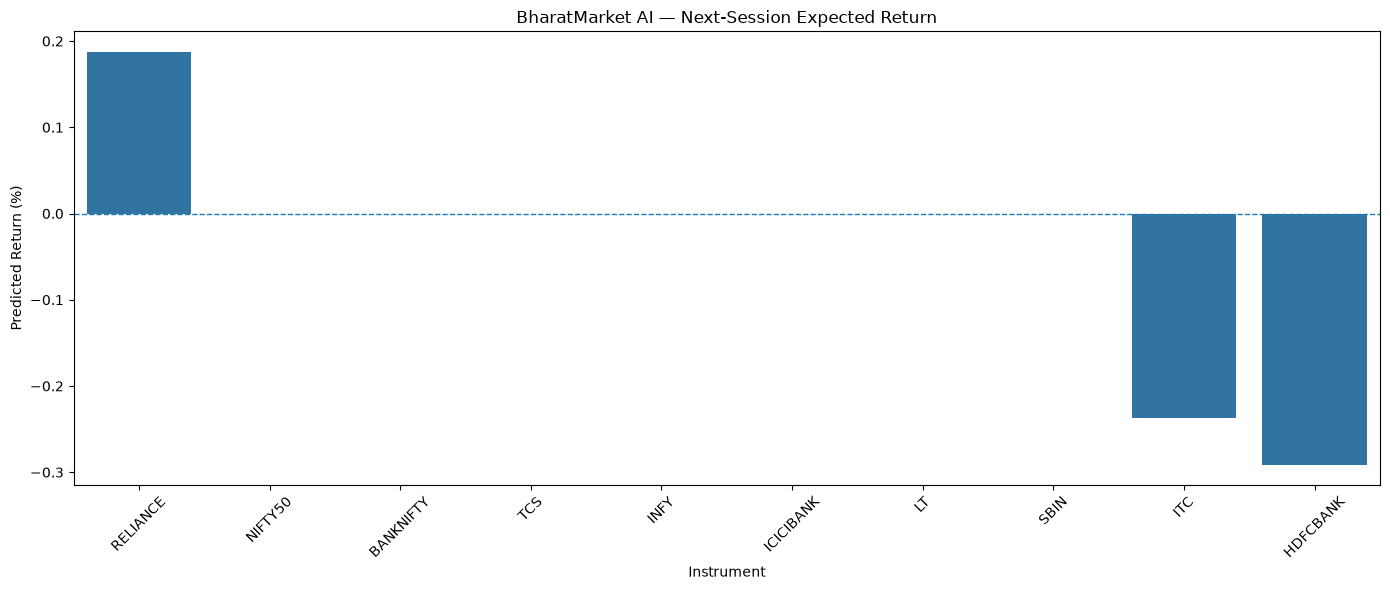

In [42]:
if not forecast_df.empty:

    chart_data = forecast_df.sort_values(
        "Expected_Change_Percent",
        ascending=False
    )

    plt.figure(figsize=(14, 6))

    sns.barplot(
        data=chart_data,
        x="Instrument",
        y="Expected_Change_Percent"
    )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    plt.title(
        "BharatMarket AI — Next-Session Expected Return"
    )

    plt.xlabel("Instrument")
    plt.ylabel("Predicted Return (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "return_based_forecast_comparison.png",
        dpi=300
    )

    plt.show()

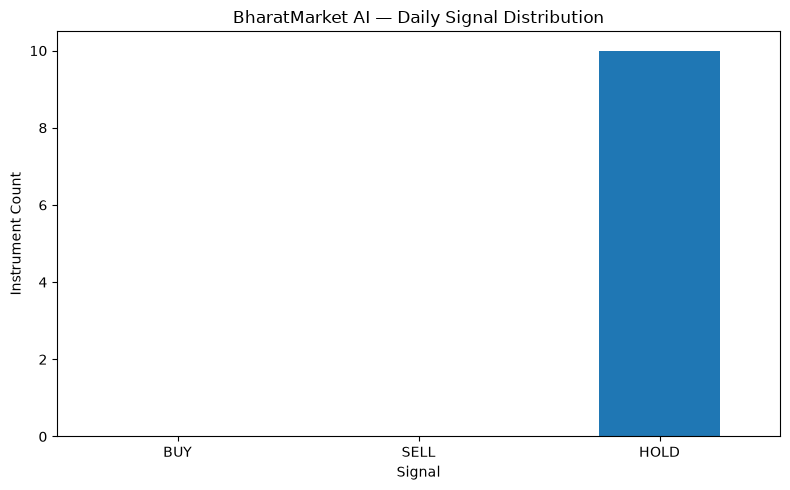

In [43]:
if not forecast_df.empty:

    signal_counts = (
        forecast_df["Signal"]
        .value_counts()
        .reindex(["BUY", "SELL", "HOLD"], fill_value=0)
    )

    plt.figure(figsize=(8, 5))

    signal_counts.plot(kind="bar")

    plt.title(
        "BharatMarket AI — Daily Signal Distribution"
    )

    plt.xlabel("Signal")
    plt.ylabel("Instrument Count")
    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "return_based_signal_distribution.png",
        dpi=300
    )

    plt.show()

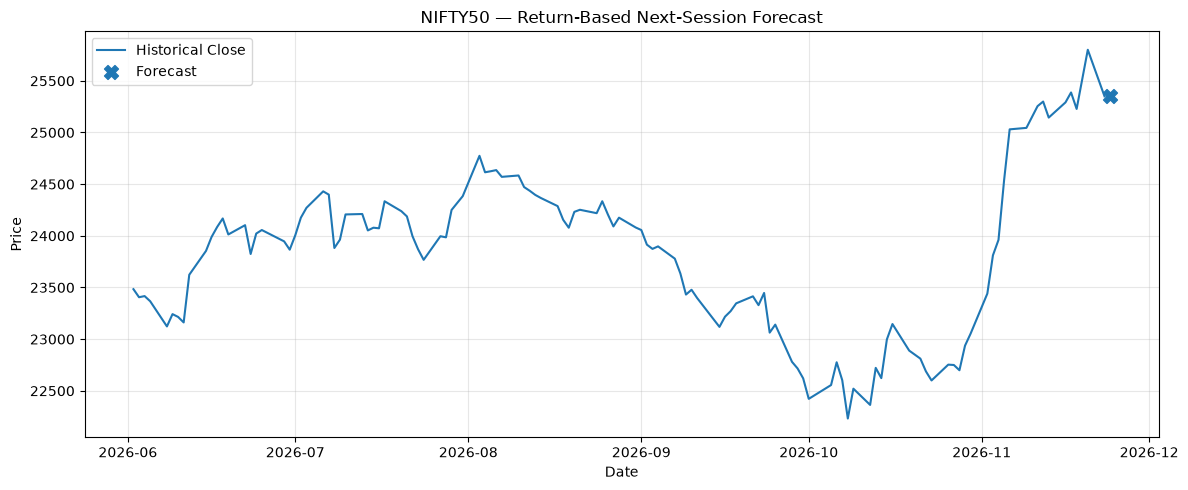

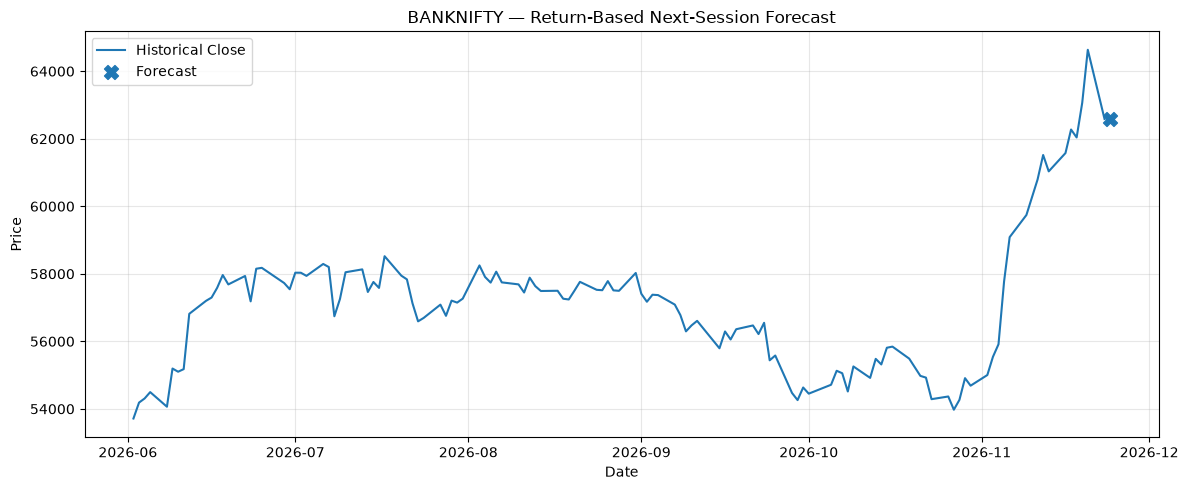

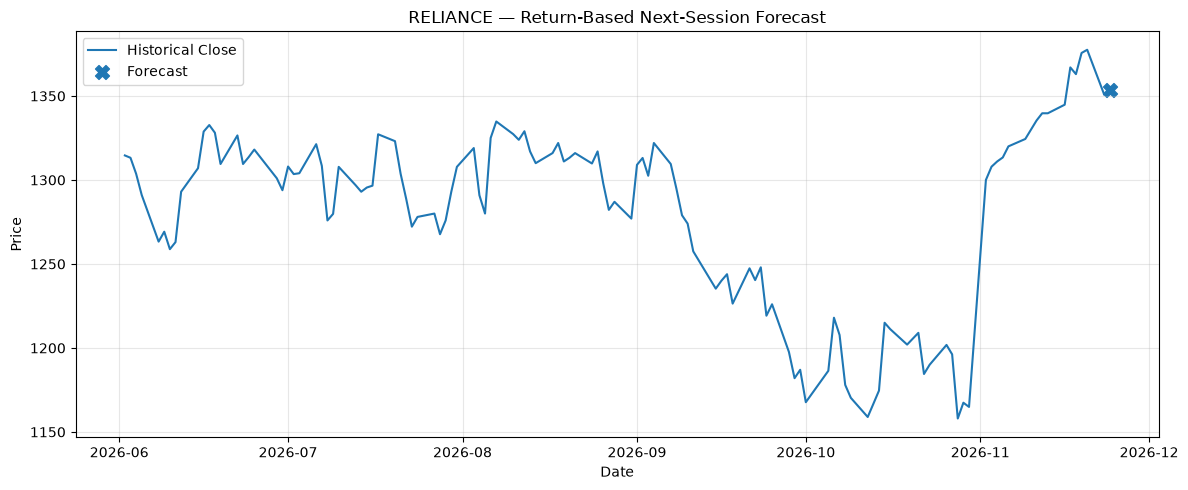

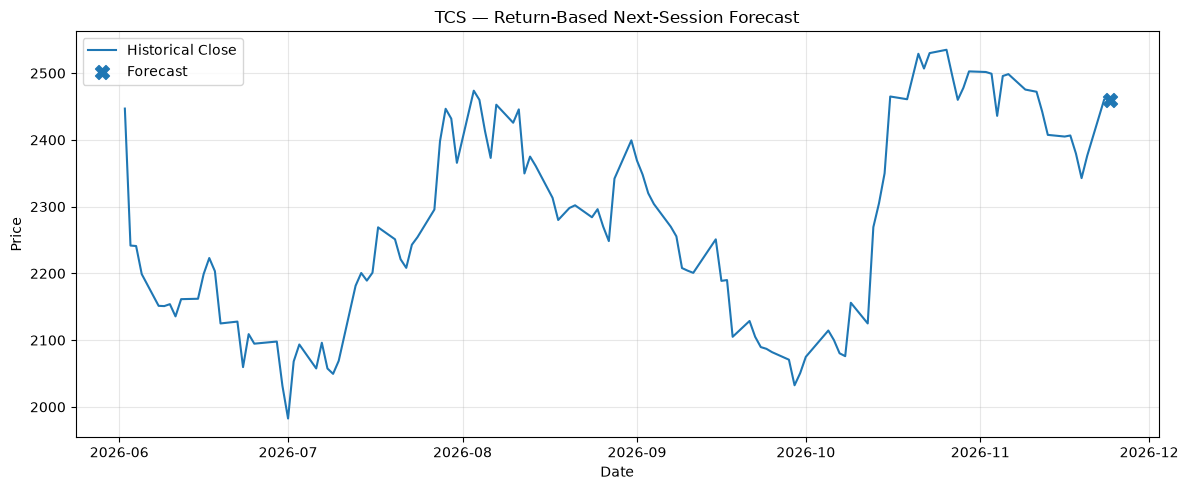

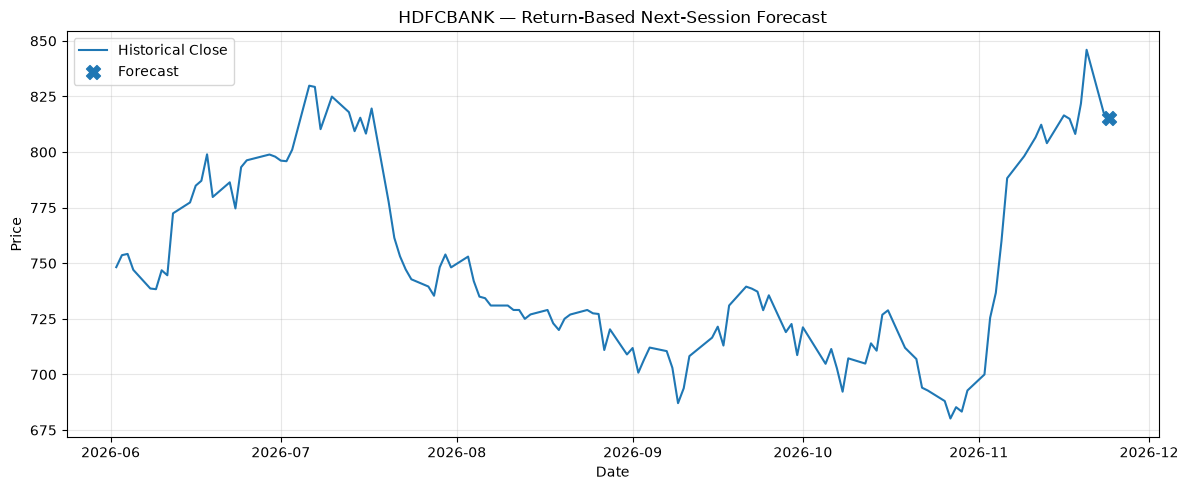

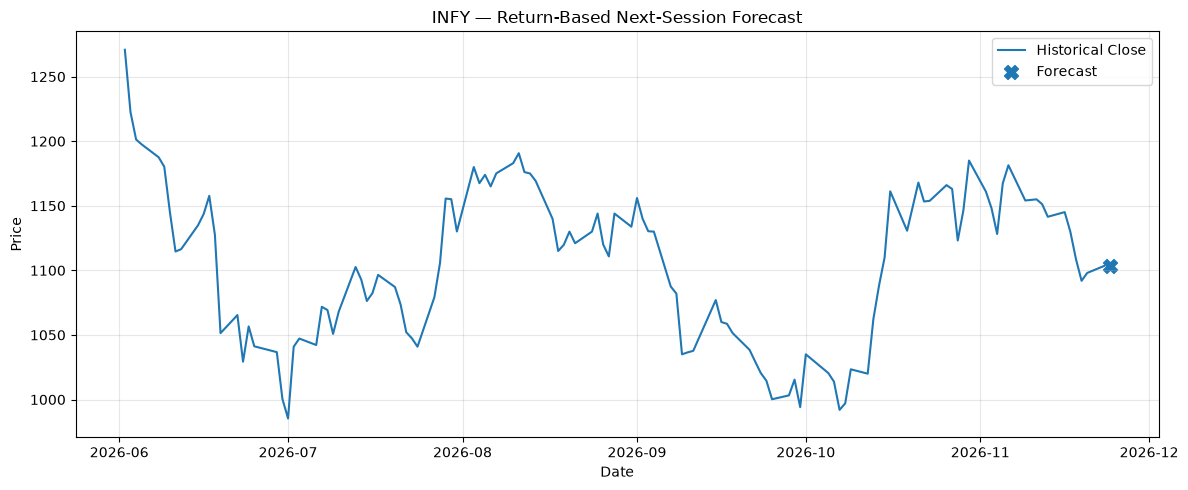

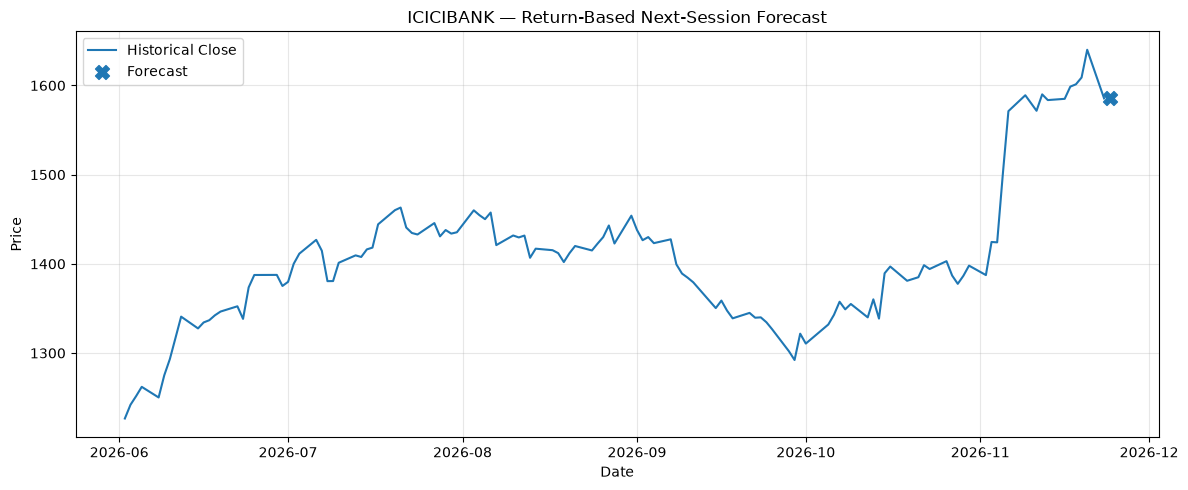

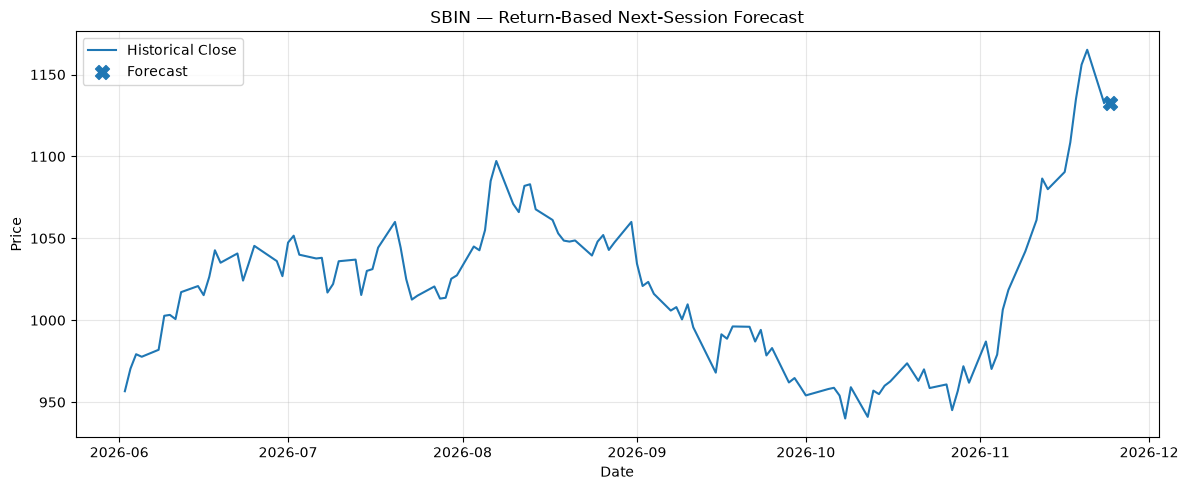

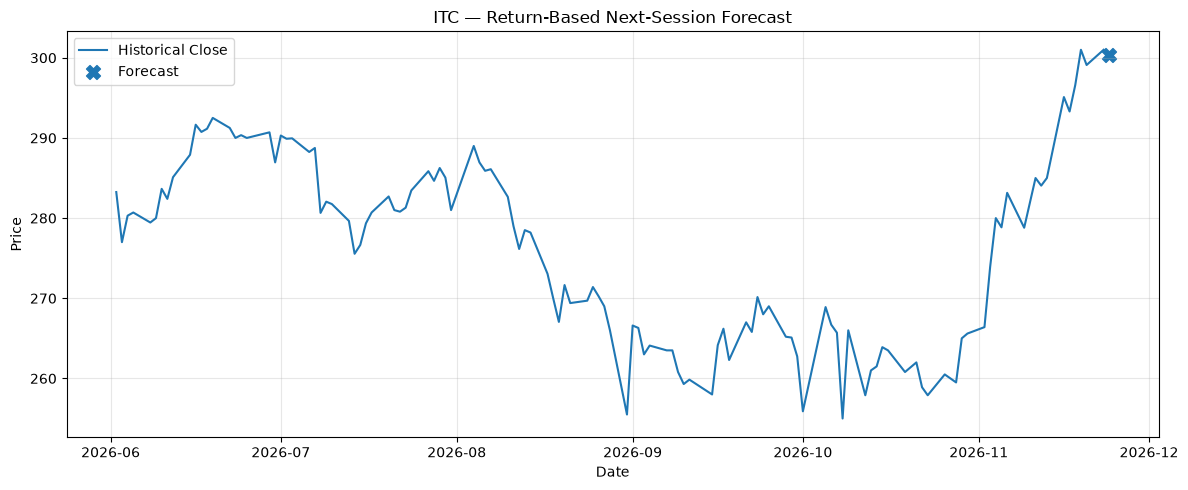

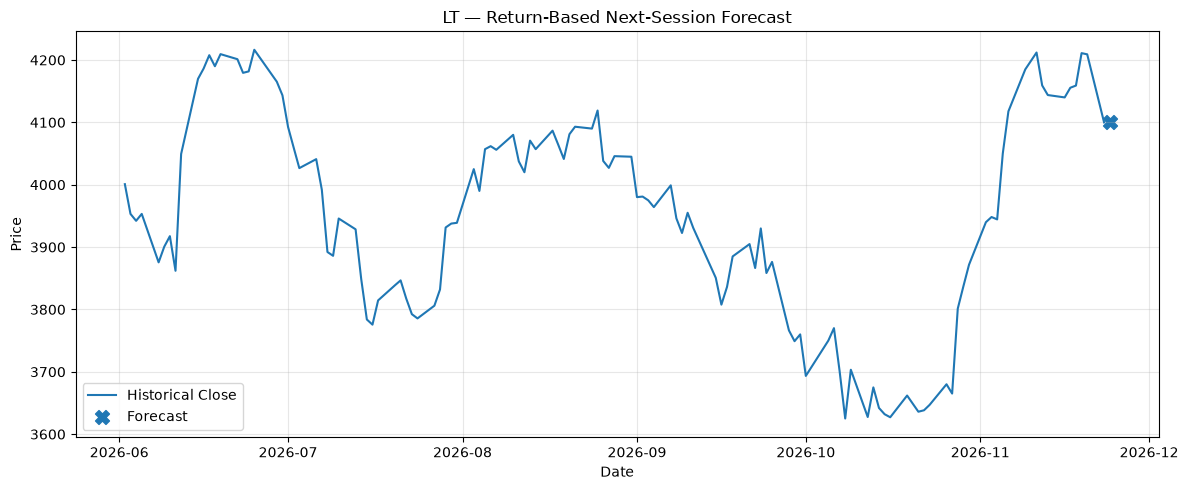

In [44]:
for _, row in forecast_df.iterrows():

    symbol = row["Instrument"]

    df = load_latest_feature_data(symbol).tail(120)

    plt.figure(figsize=(12, 5))

    plt.plot(
        df["date"],
        df["close"],
        label="Historical Close"
    )

    plt.scatter(
        [row["Estimated_Next_Session"]],
        [row["Predicted_Next_Close"]],
        marker="X",
        s=100,
        label="Forecast"
    )

    plt.title(
        f"{symbol} — Return-Based Next-Session Forecast"
    )

    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / f"{symbol}_return_based_forecast.png",
        dpi=300
    )

    plt.show()

In [45]:
forecast_file = (
    FORECAST_DIR / "bharatmarket_return_based_forecasts.csv"
)

signals_file = (
    REPORT_DIR / "bharatmarket_return_based_signals.csv"
)

errors_file = (
    REPORT_DIR / "return_based_forecast_errors.csv"
)

forecast_df.to_csv(
    forecast_file,
    index=False
)

signals_df.to_csv(
    signals_file,
    index=False
)

# Always write headers, even if there are no errors.
pd.DataFrame(
    forecast_errors,
    columns=["Instrument", "Error"]
).to_csv(
    errors_file,
    index=False
)

print("Forecasts saved:", forecast_file)
print("Signals saved:", signals_file)
print("Errors saved:", errors_file)

Forecasts saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\data\forecasts\bharatmarket_return_based_forecasts.csv
Signals saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports\bharatmarket_return_based_signals.csv
Errors saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports\return_based_forecast_errors.csv


In [46]:
print("=" * 70)
print("BHARATMARKET AI — NOTEBOOK 09 SUMMARY")
print("=" * 70)

print("\nConfigured instruments:", len(INSTRUMENTS))
print("Successful forecasts:", len(forecast_df))
print("Unique instruments forecasted:", forecast_df["Instrument"].nunique())
print("Forecast errors:", len(forecast_errors))

print("\nSelected models:")
display(
    forecast_df[
        ["Instrument", "Model"]
    ]
)

print("\nSignal distribution:")
display(
    forecast_df["Signal"].value_counts()
)

print("\nComplete forecast table:")

display(
    forecast_df[
        [
            "Instrument",
            "Last_Data_Date",
            "Estimated_Next_Session",
            "Current_Close",
            "Predicted_Next_Return_Pct",
            "Predicted_Next_Close",
            "Signal",
            "Indicative_Entry",
            "Stop_Loss",
            "Target_1",
            "Target_2",
            "Target_3"
        ]
    ]
)

expected = set(INSTRUMENTS)
actual = set(forecast_df["Instrument"])

if (
    len(forecast_df) == len(INSTRUMENTS)
    and actual == expected
    and len(forecast_errors) == 0
):
    print("\nSUCCESS: All 10 forecasts generated.")
else:
    print("\nCHECK REQUIRED: Some instruments are missing or failed.")

print("\nNotebook 09 completed.")

BHARATMARKET AI — NOTEBOOK 09 SUMMARY

Configured instruments: 10
Successful forecasts: 10
Unique instruments forecasted: 10
Forecast errors: 0

Selected models:


,Instrument,Model
0,NIFTY50,Zero Return Baseline
1,BANKNIFTY,Zero Return Baseline
2,RELIANCE,Gradient Boosting
3,TCS,Zero Return Baseline
4,HDFCBANK,Gradient Boosting
5,INFY,Zero Return Baseline
6,ICICIBANK,Zero Return Baseline
7,SBIN,Zero Return Baseline
8,ITC,Linear Regression
9,LT,Zero Return Baseline



Signal distribution:


Signal
HOLD    10
Name: count, dtype: int64


Complete forecast table:


,Instrument,Last_Data_Date,Estimated_Next_Session,Current_Close,Predicted_Next_Return_Pct,Predicted_Next_Close,Signal,Indicative_Entry,Stop_Loss,Target_1,Target_2,Target_3
0,NIFTY50,2026-11-23,2026-11-24,25349.650391,0.000000,25349.650391,HOLD,25349.650391,NaN,NaN,NaN,NaN
1,BANKNIFTY,2026-11-23,2026-11-24,62585.351562,0.000000,62585.351562,HOLD,62585.351562,NaN,NaN,NaN,NaN
2,RELIANCE,2026-11-23,2026-11-24,1351.000000,0.187375,1353.531436,HOLD,1351.000000,NaN,NaN,NaN,NaN
3,TCS,2026-11-23,2026-11-24,2460.000000,0.000000,2460.000000,HOLD,2460.000000,NaN,NaN,NaN,NaN
4,HDFCBANK,2026-11-23,2026-11-24,817.799988,-0.291074,815.419585,HOLD,817.799988,NaN,NaN,NaN,NaN
5,INFY,2026-11-23,2026-11-24,1103.400024,0.000000,1103.400024,HOLD,1103.400024,NaN,NaN,NaN,NaN
6,ICICIBANK,2026-11-23,2026-11-24,1585.500000,0.000000,1585.500000,HOLD,1585.500000,NaN,NaN,NaN,NaN
7,SBIN,2026-11-23,2026-11-24,1132.650024,0.000000,1132.650024,HOLD,1132.650024,NaN,NaN,NaN,NaN
8,ITC,2026-11-23,2026-11-24,301.000000,-0.237212,300.285992,HOLD,301.000000,NaN,NaN,NaN,NaN
9,LT,2026-11-23,2026-11-24,4099.899902,0.000000,4099.899902,HOLD,4099.899902,NaN,NaN,NaN,NaN



SUCCESS: All 10 forecasts generated.

Notebook 09 completed.
